<a href="https://colab.research.google.com/github/tthao1106/MachineLearning/blob/main/BT1_HoiQuy/BT1_H%E1%BB%93i_quy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Hệ số chặn (Intercept): 541.9556306125319
Hệ số hồi quy (Coefficients): 24.97708023765855
Mean Squared Error (MSE): 36710.12987885714
R2:  0.9624106935744278


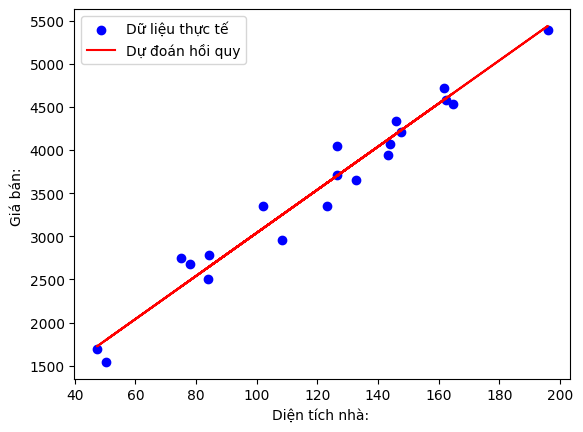

In [8]:
#Bài tập ở lớp 1: Giả sử có một tập dữ liệu giả định với các cột Diện tích nhà (m2) và Giá bán (triệu VND).
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(0) #cố định giá trị ngẫu nhiên đầu vào

n = 100

dienTich = np.random.uniform(30, 200, n).reshape(-1, 1)
giaBan = 500 + 25 * dienTich + np.random.randn(n, 1) * 200

x_train, x_test, y_train, y_test = train_test_split(dienTich, giaBan, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

mse = mean_squared_error(y_test, y_pred)
print(f"Hệ số chặn (Intercept): {model.intercept_[0]}")
print(f"Hệ số hồi quy (Coefficients): {model.coef_[0][0]}")
print(f"Mean Squared Error (MSE): {mse}")
print("R2: ", r2_score(y_test, y_pred))

plt.scatter(x_test, y_test, color='blue', label="Dữ liệu thực tế")
plt.plot(x_test, y_pred, color="red", label="Dự đoán hồi quy")
plt.xlabel("Diện tích nhà: ")
plt.ylabel("Giá bán: ")
plt.legend()
plt.show()

Độ chính xác (Accuracy): 0.9
Ma trận nhầm lẫn (Confusion Matrix):
[[18  2]
 [ 2 18]]
Báo cáo phân loại (Classification Report):
              precision    recall  f1-score   support

           0       0.90      0.90      0.90        20
           1       0.90      0.90      0.90        20

    accuracy                           0.90        40
   macro avg       0.90      0.90      0.90        40
weighted avg       0.90      0.90      0.90        40



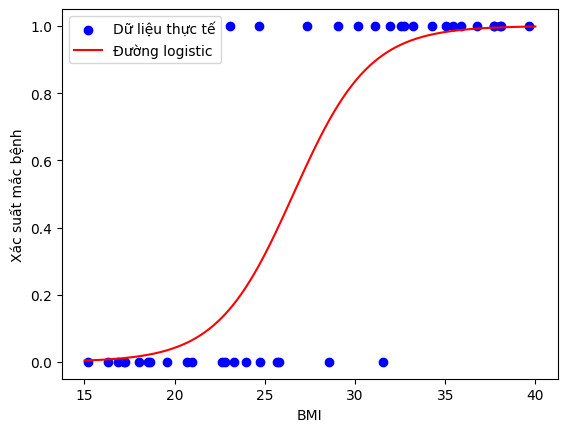

In [11]:
#Bài tập ở lớp 2: Dự đoán khả năng mắc bệnh dựa trên chỉ số BMI
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

np.random.seed(42)
n = 200
X = np.random.uniform(15, 40, (n, 1))# BMI
xac_suat = 1 / (1 + np.exp(-(X - 27) * 0.5))
y = (np.random.rand(n, 1) < xac_suat).astype(int).ravel()#Nhãn Mắc bệnh (0/1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred) #pred = prediction (giá trị dự đoán)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print(f"Độ chính xác (Accuracy): {accuracy}")
print("Ma trận nhầm lẫn (Confusion Matrix):")
print(conf_matrix)
print("Báo cáo phân loại (Classification Report):")
print(class_report)

y_prob = model.predict_proba(X_test)[:, 1]

x_line = np.linspace(15, 40, 300).reshape(-1, 1)
plt.scatter(X_test, y_test, color="blue", label="Dữ liệu thực tế")
plt.plot(x_line, model.predict_proba(x_line)[:, 1], color="red", label="Đường logistic")
plt.xlabel("BMI")
plt.ylabel("Xác suất mắc bệnh")
plt.legend()
plt.show()

   MedInc  HouseAge  AveRooms  ...  Latitude  Longitude  MedHouseVal
0  8.3252      41.0  6.984127  ...     37.88    -122.23        4.526
1  8.3014      21.0  6.238137  ...     37.86    -122.22        3.585
2  7.2574      52.0  8.288136  ...     37.85    -122.24        3.521
3  5.6431      52.0  5.817352  ...     37.85    -122.25        3.413
4  3.8462      52.0  6.281853  ...     37.85    -122.25        3.422

[5 rows x 9 columns]
             MedInc      HouseAge  ...     Longitude   MedHouseVal
count  20640.000000  20640.000000  ...  20640.000000  20640.000000
mean       3.870671     28.639486  ...   -119.569704      2.068558
std        1.899822     12.585558  ...      2.003532      1.153956
min        0.499900      1.000000  ...   -124.350000      0.149990
25%        2.563400     18.000000  ...   -121.800000      1.196000
50%        3.534800     29.000000  ...   -118.490000      1.797000
75%        4.743250     37.000000  ...   -118.010000      2.647250
max       15.000100     52.0

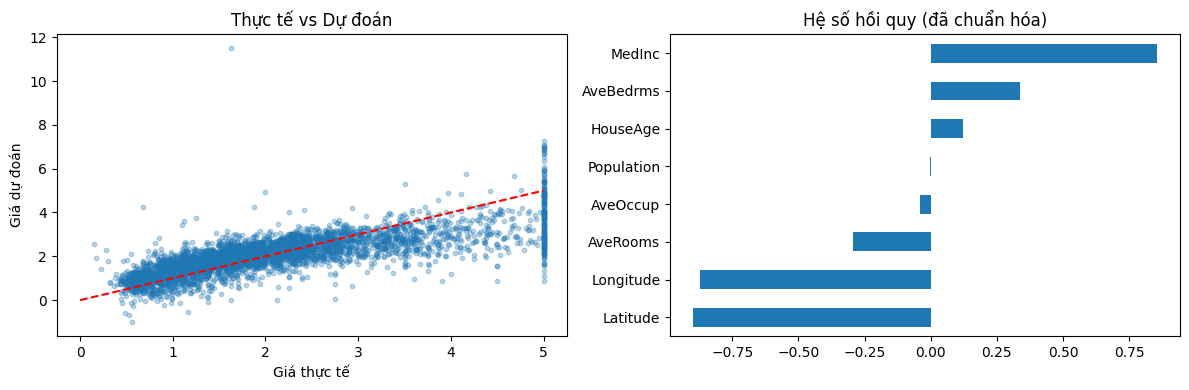

In [10]:
#Bài 3: Chọn 1 bộ dữ liệu tùy ý và thực hiện các bước cần thiết để có được mô hình hồi quy ứng với bộ dữ liệu đã chọn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Tải dữ liệu
data = fetch_california_housing(as_frame=True)
df = data.frame

# 2. Khám phá dữ liệu
print(df.head())
print(df.describe())
print("Thiếu dữ liệu:\n", df.isnull().sum())
print("Tương quan với giá nhà:\n", df.corr()["MedHouseVal"].sort_values(ascending=False))

# 3. Tách đặc trưng (X) và nhãn (y)
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]

# 4. Chia train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Chuẩn hóa (fit trên train, áp dụng cho test)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# 6. Huấn luyện mô hình
model = LinearRegression()
model.fit(X_train_s, y_train)

# 7. Dự đoán và đánh giá
y_pred = model.predict(X_test_s)
mse = mean_squared_error(y_test, y_pred)
print("MSE:", mse)
print("RMSE:", np.sqrt(mse))
print("R2:", r2_score(y_test, y_pred))

# 8. Xem mức ảnh hưởng của từng đặc trưng
heso = pd.Series(model.coef_, index=X.columns).sort_values()
print(heso)

# 9. Trực quan hóa
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(y_test, y_pred, alpha=0.3, s=10)
axes[0].plot([0, 5], [0, 5], "r--")
axes[0].set_xlabel("Giá thực tế")
axes[0].set_ylabel("Giá dự đoán")
axes[0].set_title("Thực tế vs Dự đoán")

heso.plot(kind="barh", ax=axes[1])
axes[1].set_title("Hệ số hồi quy (đã chuẩn hóa)")

plt.tight_layout()
plt.show()

 Nhiễu |  Intercept |   Slope |        MSE |     R2
----------------------------------------------------
     0 |     500.00 |   25.00 |        0.0 |  1.000
    50 |     505.65 |   24.88 |     2639.1 |  0.998
   200 |     522.61 |   24.53 |    42225.3 |  0.968
   500 |     556.51 |   23.84 |   263908.1 |  0.816
  1000 |     613.03 |   22.67 |  1055632.5 |  0.480


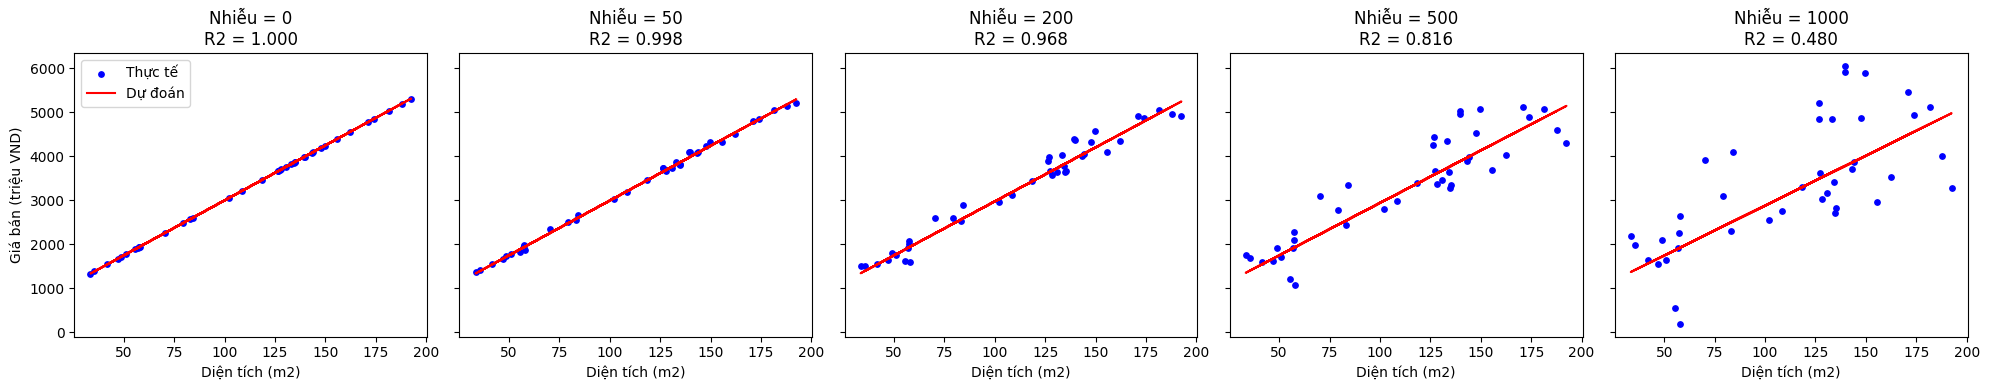

In [12]:
#Bài tập về nhà 1: Thay đổi điều kiện sinh dữ liệu, ví dụ tăng độ nhiễu để kiểm tra độ chính xác của mô hình
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

def tao_du_lieu(n, noise, seed=0):
    rng = np.random.RandomState(seed)
    dien_tich = rng.uniform(30, 200, (n, 1))# m2
    gia_ban = 500 + 25 * dien_tich + rng.randn(n, 1) * noise # triệu VND
    return dien_tich, gia_ban

n = 200
cac_muc_nhieu = [0, 50, 200, 500, 1000]

fig, axes = plt.subplots(1, len(cac_muc_nhieu), figsize=(20, 4), sharey=True)

print(f"{'Nhiễu':>6} | {'Intercept':>10} | {'Slope':>7} | {'MSE':>10} | {'R2':>6}")
print("-" * 52)

for ax, noise in zip(axes, cac_muc_nhieu):
    x, y = tao_du_lieu(n, noise)
    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.2, random_state=0)

    model = LinearRegression()
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"{noise:>6} | {model.intercept_[0]:>10.2f} | {model.coef_[0][0]:>7.2f} | {mse:>10.1f} | {r2:>6.3f}")

    ax.scatter(x_test, y_test, color="blue", s=15, label="Thực tế")
    ax.plot(x_test, y_pred, color="red", label="Dự đoán")
    ax.set_title(f"Nhiễu = {noise}\nR2 = {r2:.3f}")
    ax.set_xlabel("Diện tích (m2)")

axes[0].set_ylabel("Giá bán (triệu VND)")
axes[0].legend()
plt.tight_layout()
plt.show()

 Ngưỡng  Accuracy  Precision  Recall  TN  FP  FN  TP  Số ca dự đoán bệnh
    0.3      0.94      0.961   0.925  45   2   4  49                  51
    0.4      0.95      1.000   0.906  47   0   5  48                  48
    0.5      0.94      1.000   0.887  47   0   6  47                  47
    0.6      0.93      1.000   0.868  47   0   7  46                  46
    0.7      0.91      1.000   0.830  47   0   9  44                  44
    0.8      0.90      1.000   0.811  47   0  10  43                  43
    0.9      0.83      1.000   0.679  47   0  17  36                  36


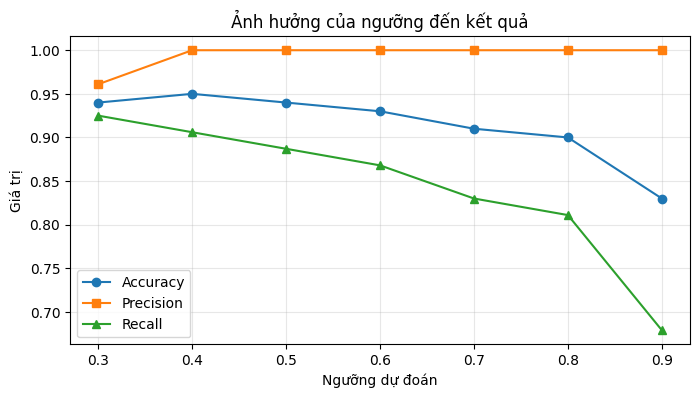

In [13]:
#Bài tập về nhà 2:  Đổi ngưỡng dự đoán xác suất (ví dụ 0.6, 0.7,… thay vì 0.5) và quan sát sự thay đổi trong kết quả dự đoán, tiếp tục từ Bài tập tại lớp 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             precision_score, recall_score)

np.random.seed(42)
n = 500
X = np.random.uniform(15, 40, (n, 1))
xac_suat = 1 / (1 + np.exp(-(X - 27) * 0.5))
y = (np.random.rand(n, 1) < xac_suat).astype(int).ravel()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

model = LogisticRegression()
model.fit(X_train, y_train)

# Xác suất mắc bệnh trên tập kiểm tra
y_prob = model.predict_proba(X_test)[:, 1]

# Thử nhiều ngưỡng
cac_nguong = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
ket_qua = []

for nguong in cac_nguong:
    y_pred = (y_prob >= nguong).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    ket_qua.append({
        "Ngưỡng": nguong,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Số ca dự đoán bệnh": y_pred.sum()
    })

bang = pd.DataFrame(ket_qua).round(3)
print(bang.to_string(index=False))

# Vẽ biểu đồ so sánh
plt.figure(figsize=(8, 4))
plt.plot(bang["Ngưỡng"], bang["Accuracy"], "o-", label="Accuracy")
plt.plot(bang["Ngưỡng"], bang["Precision"], "s-", label="Precision")
plt.plot(bang["Ngưỡng"], bang["Recall"], "^-", label="Recall")
plt.xlabel("Ngưỡng dự đoán")
plt.ylabel("Giá trị")
plt.title("Ảnh hưởng của ngưỡng đến kết quả")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

MSE: 24.291119474973478
R2 score: 0.6687594935356326
NOX       -17.202633
DIS        -1.447865
PTRATIO    -0.915456
LSTAT      -0.508571
CRIM       -0.113056
TAX        -0.010647
AGE        -0.006296
B           0.012351
ZN          0.030110
INDUS       0.040381
RAD         0.262430
CHAS        2.784438
RM          4.438835
dtype: float64


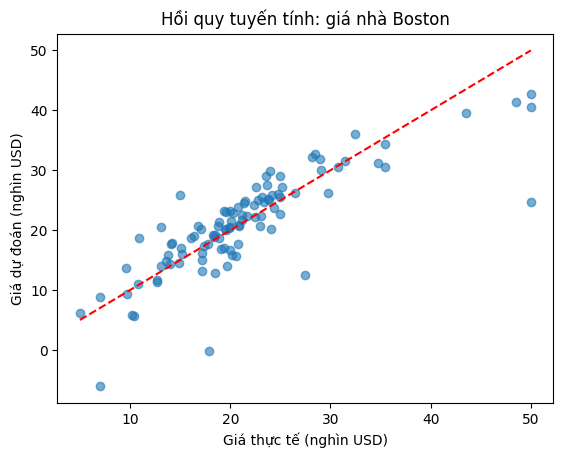

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Tải tập dữ liệu Boston Housing
data_url = "http://lib.stat.cmu.edu/datasets/boston"
raw_df = pd.read_csv(data_url, sep=r"\s+", skiprows=22, header=None)
X = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
y = raw_df.values[1::2, 2]

cot = ["CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE",
       "DIS", "RAD", "TAX", "PTRATIO", "B", "LSTAT"]
X = pd.DataFrame(X, columns=cot)

# 2. Chia tập huấn luyện và kiểm tra
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

# 3. Huấn luyện và dự đoán
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# 4. Đánh giá trên tập kiểm tra
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("MSE:", mse)
print("R2 score:", r2)

# (Thêm) Hệ số của từng thuộc tính
print(pd.Series(model.coef_, index=cot).sort_values())

# (Thêm) Trực quan hóa
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--")
plt.xlabel("Giá thực tế (nghìn USD)")
plt.ylabel("Giá dự đoán (nghìn USD)")
plt.title("Hồi quy tuyến tính: giá nhà Boston")
plt.show()